<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/lesson8/Lesson8_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 8 — Functions, Limits and Continuity: Describing How a Neuron Responds

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 3 — Calculus I\
**Lesson:** Lesson 8\
**Notebook type:** Teaching notebook

> *"A tuning curve is a function. Before asking how fast it changes, ask what it is, where it is defined, what it does at its edges, and whether you sampled it finely enough to know."*

---

### From vectors to functions

Weeks 1 and 2 treated neural activity as vectors and matrices: snapshots, and linear maps between them. But much of neuroscience is about **how one quantity depends on another**: firing rate on stimulus contrast, on input current, on hand speed; membrane voltage on time; the output of an artificial neuron on its weighted input. Each of these is a **function**.

Calculus, which starts here, is the mathematics of how functions change. This lesson lays the groundwork: what a function is, the families that keep appearing in neuroscience and machine learning (linear, exponential, logarithmic, sigmoid, ReLU, piecewise), how functions combine and invert, what happens at their edges (**limits** and **asymptotes**), where they jump (**continuity**), and how sampling and plotting can lie about them. The mini-lab asks what function best describes a motor-cortex neuron's response to hand speed, and how far its fitted shape can be trusted.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-7.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-7.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: four measurements, three stories**

An experimenter measures a visual neuron's firing rate at four stimulus contrasts: 0, 25, 50 and 100%. Three researchers fit three different functions to the same four points. All three pass close to every measurement.

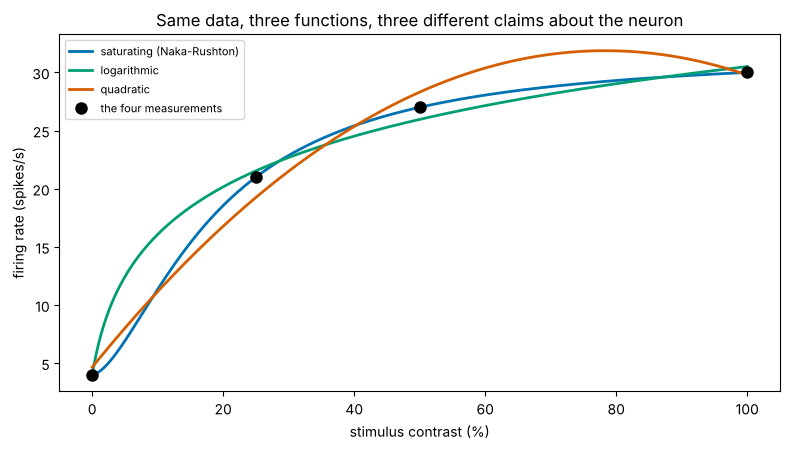

saturating (Naka-Rushton) : largest miss at the data  0.0 spikes/s;  predicted rate at 10% =  11.4, at 75% =  29.1, at 200% (impossible) =   31.2
logarithmic               : largest miss at the data  1.0 spikes/s;  predicted rate at 10% =  16.1, at 75% =  28.6, at 200% (impossible) =   35.1
quadratic                 : largest miss at the data  1.7 spikes/s;  predicted rate at 10% =  11.2, at 75% =  31.8, at 200% (impossible) =  -33.8


In [3]:
contrast_meas = np.array([0.0, 25.0, 50.0, 100.0])                       # stimulus contrast (%)
rate_meas = np.array([4.0, 21.0, 27.0, 30.0])                           # mean firing rate (spikes/s)

c = np.linspace(0, 100, 501)                                             # a fine grid of contrasts, shape (501,)
import warnings
from scipy.optimize import curve_fit, OptimizeWarning
warnings.simplefilter('ignore', OptimizeWarning)       # 4 parameters, 4 points: the fit is exact, so no error estimate exists
def naka_rushton(c, r0, rmax, c50, n):
    # A saturating "contrast-response function" widely used in vision.
    return r0 + rmax * c**n / (c**n + c50**n)
nr_params, _ = curve_fit(naka_rushton, contrast_meas, rate_meas, p0=[4, 27, 15, 2], bounds=([0, 0, 1, 0.5], [20, 100, 100, 6]))
log_coef = np.polyfit(np.log1p(contrast_meas / 2), rate_meas, 1)         # rate = a + b ln(1 + c/2), least squares
quad_coef = np.polyfit(contrast_meas, rate_meas, 2)                       # a parabola, least squares
curves = {'saturating (Naka-Rushton)': lambda x: naka_rushton(x, *nr_params),
          'logarithmic': lambda x: np.polyval(log_coef, np.log1p(x / 2)),
          'quadratic': lambda x: np.polyval(quad_coef, x)}

fig, ax = plt.subplots(figsize=(8, 4.6))
for (name, f), colour in zip(curves.items(), [PALETTE[0], PALETTE[2], PALETTE[1]]):
    ax.plot(c, f(c), color=colour, lw=2, label=name)
ax.plot(contrast_meas, rate_meas, 'ko', ms=8, label='the four measurements')
ax.set_xlabel('stimulus contrast (%)'); ax.set_ylabel('firing rate (spikes/s)')
ax.set_title('Same data, three functions, three different claims about the neuron')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
for name, f in curves.items():
    print(f"{name:<26}: largest miss at the data {np.abs(f(contrast_meas) - rate_meas).max():4.1f} spikes/s;  predicted rate at 10% = {f(10.0):5.1f}, at 75% = {f(75.0):5.1f}, at 200% (impossible) = {f(200.0):6.1f}")

The three curves agree at the measurements and disagree everywhere else: about what happens between them (at 10% contrast), about whether the neuron saturates, and wildly about inputs outside the measured **domain**. Contrast cannot exceed 100% at all, yet each formula happily returns a number for 200%.

To reason about this we need the vocabulary of this lesson: **functions** and their parameters, standard **families** of functions, **limits** (what a function approaches), **continuity** (whether it jumps), and the **sampling** needed to see a function's real shape.

# **Part 1: Functions, Variables and Parameters**

A **function** $f$ assigns to each allowed input $x$ exactly one output $f(x)$. Three pieces of information define it:

- the **domain**: the inputs that make sense (contrast from 0 to 100%; a time constant must be positive);
- the **rule**: how the output is computed;
- the **codomain** or **range**: the outputs it can produce (firing rates are never negative).

Write $f: [0, 100] \to [0, \infty)$ to state the domain and where the outputs live. **Units** matter as in Week 1: a contrast-response function takes % and returns spikes/s.

**Variables versus parameters.** In $r(c) = r_0 + r_{\max}\dfrac{c^n}{c^n + c_{50}^n}$, the **variable** $c$ changes from one stimulus to the next. The **parameters** $r_0$ (spontaneous rate), $r_{\max}$ (maximum response above baseline), $c_{50}$ (the contrast giving half the maximum) and $n$ (steepness) are fixed for one neuron but differ between neurons. Writing $r(c;\, r_0, r_{\max}, c_{50}, n)$ makes the distinction explicit. Fitting a model (Lesson 5, and Lessons 12–15) means choosing parameters; using a model means varying the variable.

In code, a function of an array should return an array of the same shape. NumPy operations do this automatically, so write functions **vectorised**: no Python loop over inputs.

one input  : 29.758711127763206
many inputs: [ 4.   14.22 25.65 29.76 31.04]


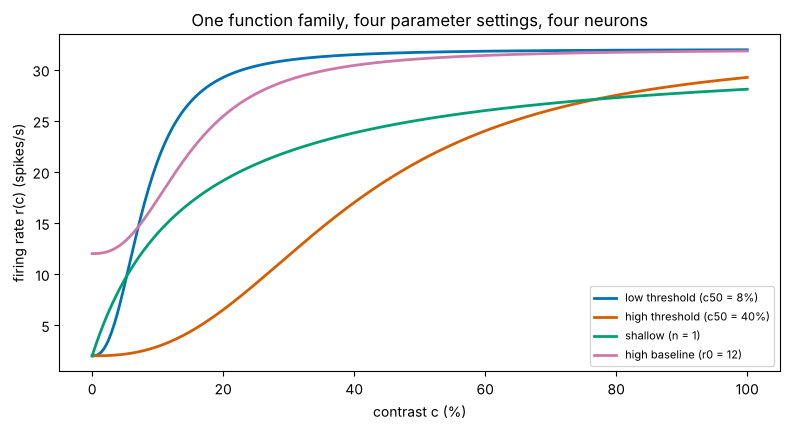

In [4]:
def contrast_response(c, r0, rmax, c50, n):
    # Naka-Rushton contrast-response function.
    # c: contrast in %, any shape. Returns firing rate in spikes/s, same shape as c.
    c = np.asarray(c, dtype=float)
    return r0 + rmax * c**n / (c**n + c50**n)

print("one input  :", contrast_response(50, r0=4, rmax=27.5, c50=13, n=2))
print("many inputs:", np.round(contrast_response(np.array([0, 10, 25, 50, 100]), 4, 27.5, 13, 2), 2))

# The same rule with different PARAMETERS describes different neurons.
neurons = {'low threshold (c50 = 8%)': (2, 30, 8, 2.5), 'high threshold (c50 = 40%)': (2, 30, 40, 2.5),
           'shallow (n = 1)': (2, 30, 15, 1.0), 'high baseline (r0 = 12)': (12, 20, 15, 2.5)}
fig, ax = plt.subplots(figsize=(8, 4.4))
for (name, p), colour, mk in zip(neurons.items(), PALETTE, MARKERS):
    ax.plot(c, contrast_response(c, *p), color=colour, lw=2, label=name)
ax.set_xlabel('contrast c (%)'); ax.set_ylabel('firing rate r(c) (spikes/s)')
ax.set_title('One function family, four parameter settings, four neurons'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Interactive version: move a parameter, watch the function change

Drag the slider to change $c_{50}$, the contrast at which the response is half its maximum. The **horizontal** position of the curve moves; its height does not.

In [5]:
c50_values = [5, 8, 12, 16, 20, 25, 30, 40, 50, 65, 80]
fig_c50 = go.Figure([go.Scatter(x=c, y=contrast_response(c, 2, 30, c50_values[0], 2.5), mode='lines', line=dict(color=PALETTE[0], width=3), name='r(c)'),
                     go.Scatter(x=[c50_values[0]], y=[2 + 15], mode='markers', marker=dict(size=12, color=PALETTE[1]), name='half-maximum point')])
fig_c50.frames = [go.Frame(name=str(k), data=[go.Scatter(x=c, y=np.round(contrast_response(c, 2, 30, v, 2.5), 3)),
                                              go.Scatter(x=[v], y=[17])]) for k, v in enumerate(c50_values)]
buttons, sliders = play_pause_and_slider(c50_values, prefix='c50 (%) = ', duration=400)
fig_c50.update_layout(xaxis_title='contrast c (%)', yaxis_title='firing rate (spikes/s)', yaxis_range=[0, 34], template='plotly_white',
                      title='Naka-Rushton function with r0 = 2, rmax = 30, n = 2.5', width=800, height=480, updatemenus=buttons, sliders=sliders)
fig_c50.show(config=PLOTLY_CONFIG)

### Four transformations of any function

Every family is a shape plus a few standard moves, and parameters usually play one of these four roles:

| Change | Effect on the graph of $f$ | Example parameter |
|---|---|---|
| $f(x - a)$ | shift **right** by $a$ | threshold, $c_{50}$, preferred direction |
| $f(x / s)$ | stretch **horizontally** by $s$ | width of a tuning curve, time constant |
| $A\,f(x)$ | stretch **vertically** by $A$ | gain, $r_{\max}$ |
| $f(x) + b$ | shift **up** by $b$ | baseline / spontaneous rate |

Note the sign in the first row: $f(x - a)$ moves the curve **right**, because the output that $f$ produced at 0 is now produced at $x = a$.

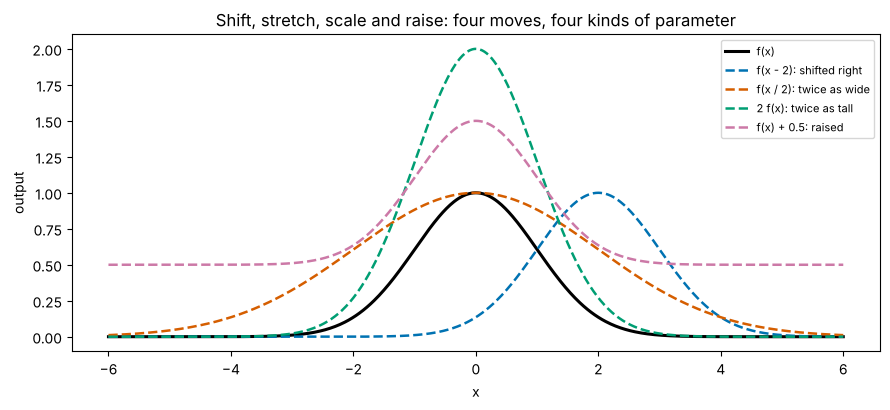

In [6]:
def bump(x):
    return np.exp(-x**2 / 2)                                   # a Gaussian bump: a common tuning-curve shape
x = np.linspace(-6, 6, 601)
moves = [('f(x)', bump(x)), ('f(x - 2): shifted right', bump(x - 2)), ('f(x / 2): twice as wide', bump(x / 2)),
         ('2 f(x): twice as tall', 2 * bump(x)), ('f(x) + 0.5: raised', bump(x) + 0.5)]
fig, ax = plt.subplots(figsize=(9, 4.2))
for (name, y), colour in zip(moves, ['black'] + PALETTE):
    ax.plot(x, y, color=colour, lw=2.2 if name == 'f(x)' else 1.8, ls='-' if name == 'f(x)' else '--', label=name)
ax.set_xlabel('x'); ax.set_ylabel('output'); ax.set_title('Shift, stretch, scale and raise: four moves, four kinds of parameter'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# **Part 2: Composition and Inverses**

### Composition: functions in a chain

Applying one function after another is **composition**: $(f \circ g)(x) = f(g(x))$. Read it from the inside out: first $g$, then $f$. The artificial neuron of Lesson 2 is a composition. A weighted sum $z = g(\mathbf{x}) = \mathbf{w}\cdot\mathbf{x} + b$ is followed by an activation $f$, giving $\text{output} = f(\mathbf{w}\cdot\mathbf{x} + b)$. A deep network is a long composition of such layers. Lesson 10's chain rule is the rule for differentiating compositions.

Order matters: in general $f(g(x)) \ne g(f(x))$, just as matrix products do not commute (Lesson 4).

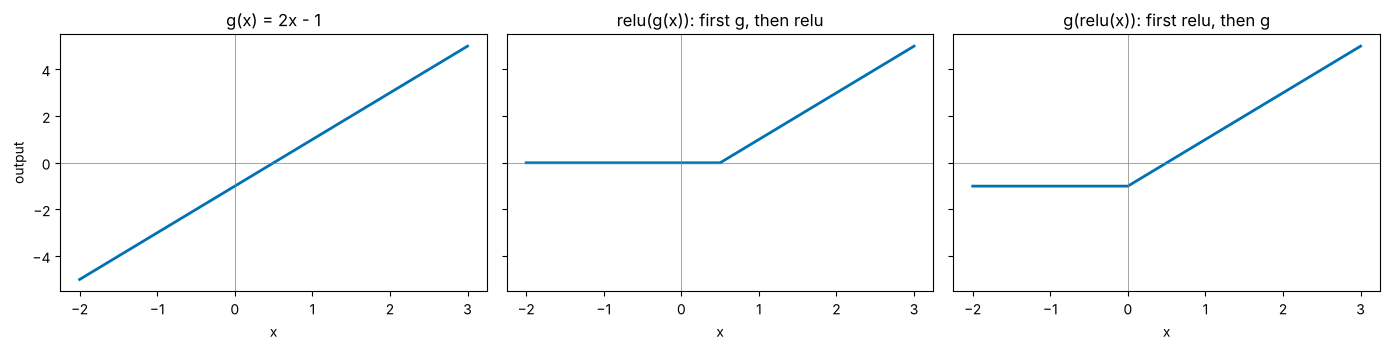

relu(g(0)) = 0.0   but  g(relu(0)) = -1.0   -> composition order matters


In [7]:
def g(x):
    return 2 * x - 1                       # an affine map: weighted input
def relu(z):
    return np.maximum(z, 0)                # the activation

xs = np.linspace(-2, 3, 501)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, y, title in [(axes[0], g(xs), 'g(x) = 2x - 1'), (axes[1], relu(g(xs)), 'relu(g(x)): first g, then relu'),
                     (axes[2], g(relu(xs)), 'g(relu(x)): first relu, then g')]:
    ax.plot(xs, y, color=PALETTE[0], lw=2); ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlabel('x'); ax.set_title(title)
axes[0].set_ylabel('output')
plt.tight_layout(); plt.show()
print("relu(g(0)) =", relu(g(0.0)), "  but  g(relu(0)) =", g(relu(0.0)), "  -> composition order matters")

### Inverses: running a function backwards

If each output comes from exactly **one** input, $f$ is **one-to-one** and has an **inverse** $f^{-1}$ with $f^{-1}(f(x)) = x$. Graphically, the inverse is the mirror image of $f$ in the line $y = x$, and $f$ is one-to-one exactly when every horizontal line meets its graph at most once (the **horizontal line test**).

Neuroscience meets inverses whenever we **decode**: a neuron's contrast-response function maps contrast to rate; reading the rate to infer the contrast uses its inverse. A strictly increasing function, like the contrast-response function, passes the test. A cosine direction-tuning curve (Lesson 2) fails it: two directions give each rate, so one neuron's rate cannot tell them apart (which is why populations, Lessons 2 and 4, are needed).

Many inverses have formulas: $\ln$ undoes $\exp$, and the **logit** $\ln\frac{p}{1-p}$ undoes the logistic sigmoid. When no formula exists, an increasing function can be inverted numerically by interpolation (`np.interp`) or by bisection (Part 6).

rate  5.0 spikes/s  ->  contrast   6.2%   (check: r(6.2) = 5.00)
rate 17.0 spikes/s  ->  contrast  15.0%   (check: r(15.0) = 17.00)
rate 30.0 spikes/s  ->  contrast  43.1%   (check: r(43.1) = 30.00)


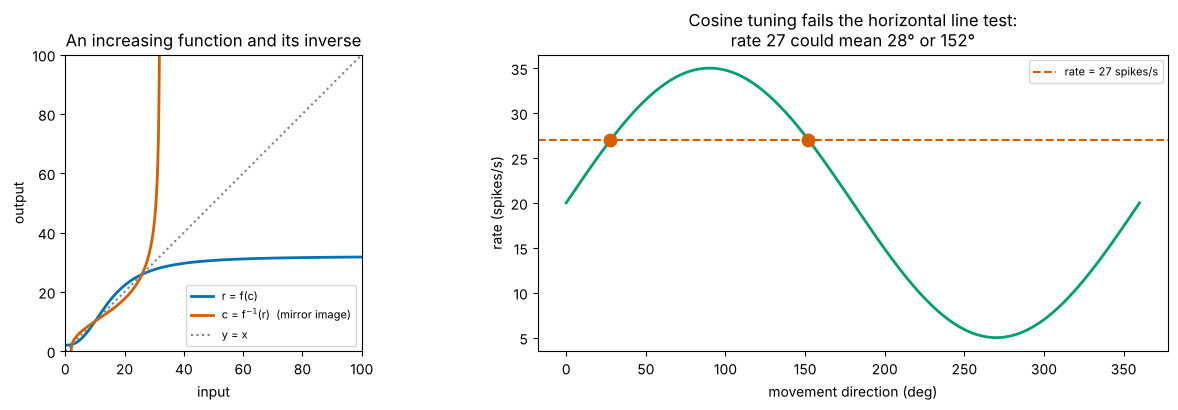

In [8]:
r_of_c = contrast_response(c, 2, 30, 15, 2.5)                       # strictly increasing on [0, 100]
def contrast_from_rate(r):
    # Numerical inverse by interpolation: swap the roles of x and y (valid because r_of_c is increasing).
    return np.interp(r, r_of_c, c)

for r_obs in [5.0, 17.0, 30.0]:
    c_hat = contrast_from_rate(r_obs)
    print(f"rate {r_obs:4.1f} spikes/s  ->  contrast {c_hat:5.1f}%   (check: r({c_hat:.1f}) = {contrast_response(c_hat, 2, 30, 15, 2.5):.2f})")

theta = np.linspace(0, 360, 721)
cos_tuning = 20 + 15 * np.cos(np.radians(theta - 90))               # preferred direction 90 deg
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(c, r_of_c, color=PALETTE[0], lw=2, label='r = f(c)')
axes[0].plot(r_of_c, c, color=PALETTE[1], lw=2, label='c = f$^{-1}$(r)  (mirror image)')
axes[0].plot([0, 100], [0, 100], color='grey', ls=':', label='y = x')
axes[0].set_xlim(0, 100); axes[0].set_ylim(0, 100); axes[0].set_aspect('equal')
axes[0].set_xlabel('input'); axes[0].set_ylabel('output'); axes[0].set_title('An increasing function and its inverse'); axes[0].legend(fontsize=8)
axes[1].plot(theta, cos_tuning, color=PALETTE[2], lw=2)
axes[1].axhline(27, color=PALETTE[1], ls='--', label='rate = 27 spikes/s')
hits = theta[np.flatnonzero(np.diff(np.sign(cos_tuning - 27)))]
axes[1].plot(hits, [27] * len(hits), 'o', color=PALETTE[1], ms=9)
axes[1].set_xlabel('movement direction (deg)'); axes[1].set_ylabel('rate (spikes/s)')
axes[1].set_title(f'Cosine tuning fails the horizontal line test:\nrate 27 could mean {hits[0]:.0f}° or {hits[1]:.0f}°'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# **Part 3: A Gallery of Function Families**

A few families appear again and again. Each is shown with its domain and range, and with where it is used.

| Family | Formula | Domain → range | Where it appears |
|---|---|---|---|
| linear / affine | $a + bx$ | $\mathbb{R} \to \mathbb{R}$ | weighted sums (Lesson 2), small-signal approximations (Lesson 9) |
| polynomial | $a_0 + a_1x + \dots + a_dx^d$ | $\mathbb{R} \to \mathbb{R}$ | Taylor approximations (Lesson 11), regression features |
| exponential | $A e^{x/s}$ or $A e^{-t/\tau}$ | $\mathbb{R} \to (0, \infty)$ | membrane decay (Lesson 21), Poisson-model link, growth |
| logarithm | $\ln x$ | $(0, \infty) \to \mathbb{R}$ | perception of intensity, log-likelihoods (Lesson 18), decibels |
| logistic sigmoid | $\sigma(x) = \dfrac{1}{1 + e^{-x}}$ | $\mathbb{R} \to (0, 1)$ | firing probability, classifiers, gates |
| tanh | $\tanh x$ | $\mathbb{R} \to (-1, 1)$ | rate models, recurrent networks |
| ReLU | $\max(0, x)$ | $\mathbb{R} \to [0, \infty)$ | threshold-linear neurons, deep networks |
| softplus | $\ln(1 + e^{x})$ | $\mathbb{R} \to (0, \infty)$ | a smooth ReLU |
| piecewise | different rules on different intervals | | threshold, linear range, saturation |
| Gaussian bump | $e^{-(x - \mu)^2/2s^2}$ | $\mathbb{R} \to (0, 1]$ | place fields, orientation tuning |
| cosine | $a + b\cos(\theta - \theta_{\text{pref}})$ | angles → $[a - b, a + b]$ | direction tuning (Lesson 2) |

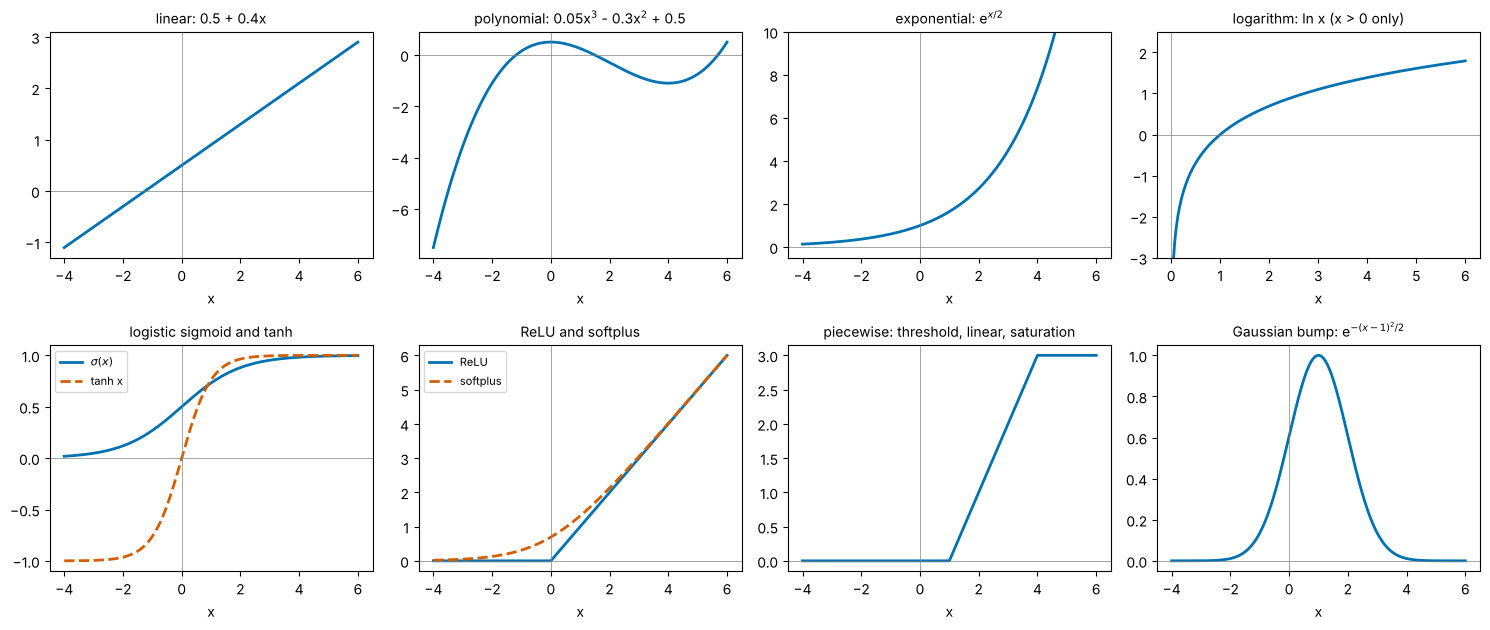

In [9]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
def softplus(x):
    return np.log1p(np.exp(-np.abs(x))) + np.maximum(x, 0)     # a numerically safe form of ln(1 + e^x)
def threshold_linear_saturating(x, threshold=1.0, gain=1.0, rmax=3.0):
    # Piecewise: 0 below threshold, linear above it, constant once the output reaches rmax.
    return np.clip(gain * (x - threshold), 0, rmax)

xg = np.linspace(-4, 6, 1001)
gallery = [
    ('linear: 0.5 + 0.4x', 0.5 + 0.4 * xg),
    ('polynomial: 0.05x$^3$ - 0.3x$^2$ + 0.5', 0.05 * xg**3 - 0.3 * xg**2 + 0.5),
    ('exponential: e$^{x/2}$', np.exp(xg / 2)),
    ('logarithm: ln x (x > 0 only)', np.where(xg > 0, np.log(np.where(xg > 0, xg, 1)), np.nan)),
    ('logistic sigmoid and tanh', None),
    ('ReLU and softplus', None),
    ('piecewise: threshold, linear, saturation', threshold_linear_saturating(xg)),
    ('Gaussian bump: e$^{-(x-1)^2/2}$', np.exp(-(xg - 1)**2 / 2)),
]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for ax, (title, y) in zip(axes.ravel(), gallery):
    if title.startswith('logistic'):
        ax.plot(xg, sigmoid(xg), color=PALETTE[0], lw=2, label='$\\sigma(x)$'); ax.plot(xg, np.tanh(xg), color=PALETTE[1], lw=2, ls='--', label='tanh x')
        ax.legend(fontsize=8)
    elif title.startswith('ReLU'):
        ax.plot(xg, np.maximum(xg, 0), color=PALETTE[0], lw=2, label='ReLU'); ax.plot(xg, softplus(xg), color=PALETTE[1], lw=2, ls='--', label='softplus')
        ax.legend(fontsize=8)
    else:
        ax.plot(xg, y, color=PALETTE[0], lw=2)
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_title(title, fontsize=10); ax.set_xlabel('x')
axes[0, 2].set_ylim(-0.5, 10); axes[0, 3].set_ylim(-3, 2.5)
plt.tight_layout(); plt.show()

### Exponentials and logarithms: the pair to know best

The exponential $e^x$ (with $e \approx 2.718$) turns **addition into multiplication**: $e^{a+b} = e^a e^b$. So a quantity that loses the same **fraction** in every equal time step decays exponentially: membrane potential relaxing back to rest, $V(t) = V_0e^{-t/\tau}$, loses 63% of its distance to rest in each time constant $\tau$ (Lesson 6's timescales were exactly this). The logarithm is its inverse, turning **multiplication into addition**: $\ln(ab) = \ln a + \ln b$, $\ln e^x = x$, defined only for positive inputs.

A practical consequence: **on a logarithmic axis an exponential becomes a straight line**, because $\ln(V_0e^{-t/\tau}) = \ln V_0 - t/\tau$. The slope is $-1/\tau$, so a line fitted to $\ln V$ (least squares, Lesson 5) estimates the time constant. The **half-life**, the time to fall by half, is $\tau\ln 2 \approx 0.69\,\tau$.

fitted time constant: 20.1 ms (true 20 ms);  half-life 13.9 ms


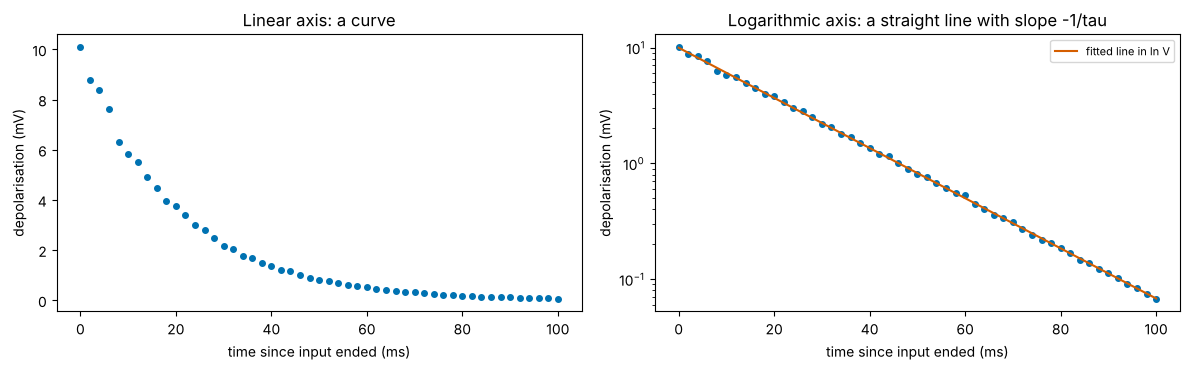

In [10]:
tau_m = 0.020                                                    # membrane time constant (s)
t_ms = np.linspace(0, 100, 51)                                   # time (ms), shape (51,)
V = 10 * np.exp(-(t_ms / 1000) / tau_m) * (1 + RNG.normal(0, 0.03, t_ms.size))   # depolarisation above rest (mV), 3% noise

slope, intercept = np.polyfit(t_ms / 1000, np.log(V), 1)          # straight-line fit to ln V
print(f"fitted time constant: {-1 / slope * 1000:.1f} ms (true {tau_m * 1000:.0f} ms);  half-life {np.log(2) * -1 / slope * 1000:.1f} ms")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(t_ms, V, 'o', ms=4, color=PALETTE[0]); axes[0].set_title('Linear axis: a curve')
axes[1].semilogy(t_ms, V, 'o', ms=4, color=PALETTE[0]); axes[1].semilogy(t_ms, np.exp(intercept + slope * t_ms / 1000), color=PALETTE[1], label='fitted line in ln V')
axes[1].set_title('Logarithmic axis: a straight line with slope -1/tau'); axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel('time since input ended (ms)'); ax.set_ylabel('depolarisation (mV)')
plt.tight_layout(); plt.show()

# **Part 4: Limits — What a Function Approaches**

The **limit** of $f(x)$ as $x$ approaches $a$, written $\lim_{x \to a} f(x) = L$, is the value $f(x)$ gets arbitrarily close to when $x$ gets close enough to $a$, **without $x$ ever being equal to $a$**. The value $f(a)$ itself plays no part: it may differ from $L$, or not exist at all.

The classic example is $f(x) = \dfrac{\sin x}{x}$, which is undefined at $x = 0$ (it would be $0/0$), yet approaches 1. A table of values shows it; this is the **numerical** way to explore a limit.

In [11]:
def sinc_like(x):
    return np.sin(x) / x

print(f"{'x':>10}  {'sin(x)/x':>12}  {'(e^x - 1)/x':>14}")
for h in [1.0, 0.5, 0.1, 0.01, 0.001, -0.001, -0.01, -0.1]:
    print(f"{h:>10}  {sinc_like(h):>12.8f}  {(np.exp(h) - 1) / h:>14.8f}")
print("At x = 0 itself, both are 0/0: undefined. The limits are 1 and 1.")

         x      sin(x)/x     (e^x - 1)/x
       1.0    0.84147098      1.71828183
       0.5    0.95885108      1.29744254
       0.1    0.99833417      1.05170918
      0.01    0.99998333      1.00501671
     0.001    0.99999983      1.00050017
    -0.001    0.99999983      0.99950017
     -0.01    0.99998333      0.99501663
      -0.1    0.99833417      0.95162582
At x = 0 itself, both are 0/0: undefined. The limits are 1 and 1.


The second column, $\frac{e^x - 1}{x} \to 1$, is not a curiosity: it is the slope of $e^x$ at 0, and Lesson 9 will define the **derivative** as exactly this kind of limit.

### One-sided limits

Sometimes the answer depends on the direction of approach. The **left limit** $\lim_{x \to a^-}$ uses only $x < a$; the **right limit** $\lim_{x \to a^+}$ only $x > a$. The two-sided limit exists only if both one-sided limits exist and agree.

A neuron that fires only above a threshold current $I_{\text{th}}$ gives an example. A perfect step (fire at 40 spikes/s or not at all) has left limit 0 and right limit 40 at $I_{\text{th}}$: no two-sided limit. An idealised integrate-and-fire neuron starts firing at an arbitrarily **low** rate just above threshold, so its rate has the same left and right limit, 0, and the curve is continuous there (Lesson 22). The approach is slow, though: the rate falls only logarithmically, so even 0.001 nA above threshold it is still about 7 spikes/s, and a coarse plot looks like a jump.

I = I_th - 0.1  : step   0.0, LIF-like   0.00   |   I = I_th + 0.1  : step  40.0, LIF-like  20.02  (spikes/s)
I = I_th - 0.01 : step   0.0, LIF-like   0.00   |   I = I_th + 0.01 : step  40.0, LIF-like  10.60  (spikes/s)
I = I_th - 0.001: step   0.0, LIF-like   0.00   |   I = I_th + 0.001: step  40.0, LIF-like   7.13  (spikes/s)


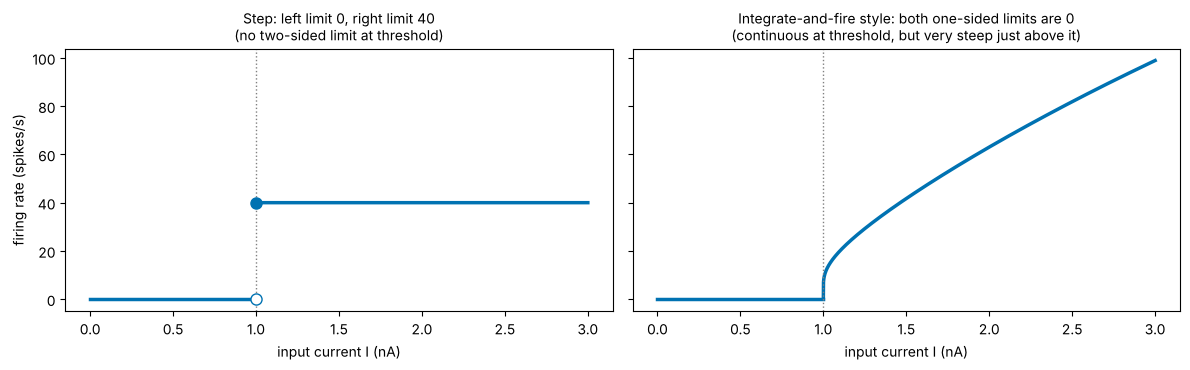

In [12]:
I = np.linspace(0, 3, 3001)                                     # input current (nA)
I_th = 1.0
step_rate = np.where(I >= I_th, 40.0, 0.0)                       # a hard step at threshold
with np.errstate(divide='ignore', invalid='ignore'):
    lif_like = np.where(I > I_th, 1 / (0.002 + 0.02 * np.log(I / np.maximum(I - I_th, 1e-12))), 0.0)   # integrate-and-fire style f-I curve (refractory 2 ms, tau 20 ms)

for h in [0.1, 0.01, 0.001]:
    print(f"I = I_th - {h:<5}: step {np.interp(I_th - h, I, step_rate):5.1f}, LIF-like {np.interp(I_th - h, I, lif_like):6.2f}   |   "
          f"I = I_th + {h:<5}: step {np.interp(I_th + h, I, step_rate):5.1f}, LIF-like {np.interp(I_th + h, I, lif_like):6.2f}  (spikes/s)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, y, title in [(axes[0], step_rate, 'Step: left limit 0, right limit 40\n(no two-sided limit at threshold)'),
                     (axes[1], lif_like, 'Integrate-and-fire style: both one-sided limits are 0\n(continuous at threshold, but very steep just above it)')]:
    ax.plot(I[I < I_th], y[I < I_th], color=PALETTE[0], lw=2.5); ax.plot(I[I >= I_th], y[I >= I_th], color=PALETTE[0], lw=2.5)
    ax.axvline(I_th, color='grey', ls=':', lw=1)
    ax.set_xlabel('input current I (nA)'); ax.set_title(title, fontsize=10)
axes[0].plot(I_th, 0, 'o', mfc='white', mec=PALETTE[0], ms=8); axes[0].plot(I_th, 40, 'o', color=PALETTE[0], ms=8)
axes[0].set_ylabel('firing rate (spikes/s)')
plt.tight_layout(); plt.show()

(Plotting the two pieces separately avoids drawing a false vertical line at the jump: Part 6 returns to this.)

### Limits at infinity and asymptotes

$\lim_{x \to \infty} f(x) = L$ means $f(x)$ gets arbitrarily close to $L$ once $x$ is large enough. The line $y = L$ is then a **horizontal asymptote**. Saturating response functions have one: as contrast or current grows, the rate approaches a ceiling ($r_0 + r_{\max}$ for the Naka-Rushton function), and the logistic sigmoid approaches 1 as $x \to \infty$ and 0 as $x \to -\infty$.

A **vertical asymptote** at $x = a$ means $f(x)$ grows without bound as $x \to a$: $\lim_{x \to 0^+}\ln x = -\infty$; the instantaneous rate $1/\text{ISI}$ grows without bound as the inter-spike interval shrinks to 0. Writing "$= \infty$" is shorthand for "grows without bound": the limit does not exist as a number.

**Parameters are not always limits.** For the Naka-Rushton function, $r_0$ is exactly the value at $c = 0$ and $r_0 + r_{\max}$ is the limit as $c \to \infty$. For a shifted logistic, $r_0 + \dfrac{A}{1 + e^{-k(x - x_{50})}}$, the value at $x = 0$ is **not** $r_0$, because the sigmoid is not yet at its lower asymptote. Always compute the limit; do not read it off a parameter name.

In [13]:
def shifted_logistic(x, r0, A, k, x50):
    return r0 + A / (1 + np.exp(-k * (x - x50)))
p = dict(r0=33.6, A=63.5, k=0.25, x50=5.04)                      # (rounded) parameters fitted to a real neuron in Part 7
for xv in [0, 10, 50, 100, 1000]:
    print(f"x = {xv:>5}: {shifted_logistic(xv, **p):6.2f}")
print(f"r0 = {p['r0']} is the limit as x -> -infinity, not the value at x = 0 ({shifted_logistic(0, **p):.1f});"
      f"  the limit as x -> +infinity is r0 + A = {p['r0'] + p['A']:.1f}")

x =     0:  47.63
x =    10:  82.85
x =    50:  97.10
x =   100:  97.10
x =  1000:  97.10
r0 = 33.6 is the limit as x -> -infinity, not the value at x = 0 (47.6);  the limit as x -> +infinity is r0 + A = 97.1


#### Interactive version: zoom in towards a limit

The slider narrows the window around $x = 0$ for $\sin(x)/x$. However closely you zoom, the curve heads for the height 1, although the point $x = 0$ itself is missing from the graph (the gap is marked).

In [14]:
widths = [10, 5, 2, 1, 0.5, 0.2, 0.1, 0.05, 0.01]
def window(w):
    xx = np.linspace(-w, w, 400)
    xx = xx[np.abs(xx) > w / 1e3]                                   # leave out x = 0, where sin(x)/x is undefined
    return xx, np.sin(xx) / xx
x0_, y0_ = window(widths[0])
fig_lim = go.Figure([go.Scatter(x=x0_, y=y0_, mode='lines', line=dict(color=PALETTE[0], width=3), name='sin(x)/x'),
                     go.Scatter(x=[0], y=[1], mode='markers', marker=dict(size=12, color='white', line=dict(color=PALETTE[1], width=3)), name='the limit 1 (x = 0 excluded)')])
fig_lim.frames = [go.Frame(name=str(k), data=[go.Scatter(x=window(w)[0], y=window(w)[1]), go.Scatter(x=[0], y=[1])],
                           layout=go.Layout(xaxis=dict(range=[-w, w]), yaxis=dict(range=[min(window(w)[1].min(), 0.99) - 0.02 * w, 1 + 0.05 * w])))
                  for k, w in enumerate(widths)]
buttons, sliders = play_pause_and_slider(widths, prefix='window half-width = ', duration=600)
fig_lim.update_layout(xaxis=dict(range=[-10, 10], title='x'), yaxis=dict(range=[-0.3, 1.1], title='sin(x)/x'), template='plotly_white',
                      title='Zooming towards x = 0', width=800, height=480, updatemenus=buttons, sliders=sliders)
fig_lim.show(config=PLOTLY_CONFIG)

### A numerical warning: limits and floating point

Computers store numbers with about 16 significant digits (Lesson 5's condition number met the same limit). Approaching a limit numerically by making $h$ ever smaller eventually fails: $\big((1 + h) - 1\big)/h$ should be exactly 1 for every $h$, but for tiny $h$ the subtraction $(1 + h) - 1$ loses almost all its digits (**catastrophic cancellation**).

h = 1e-01:  ((1 + h) - 1)/h = 1.000000000000
h = 1e-02:  ((1 + h) - 1)/h = 1.000000000000
h = 1e-03:  ((1 + h) - 1)/h = 1.000000000000
h = 1e-04:  ((1 + h) - 1)/h = 1.000000000000
h = 1e-05:  ((1 + h) - 1)/h = 1.000000000007
h = 1e-06:  ((1 + h) - 1)/h = 0.999999999918
h = 1e-07:  ((1 + h) - 1)/h = 1.000000000584
h = 1e-08:  ((1 + h) - 1)/h = 0.999999993923
h = 1e-09:  ((1 + h) - 1)/h = 1.000000082740
h = 1e-10:  ((1 + h) - 1)/h = 1.000000082740
h = 1e-11:  ((1 + h) - 1)/h = 1.000000082740
h = 1e-12:  ((1 + h) - 1)/h = 1.000088900582
h = 1e-13:  ((1 + h) - 1)/h = 0.999200722163
h = 1e-14:  ((1 + h) - 1)/h = 0.999200722163
h = 1e-15:  ((1 + h) - 1)/h = 1.110223024625
h = 1e-16:  ((1 + h) - 1)/h = 0.000000000000
h = 1e-17:  ((1 + h) - 1)/h = 0.000000000000


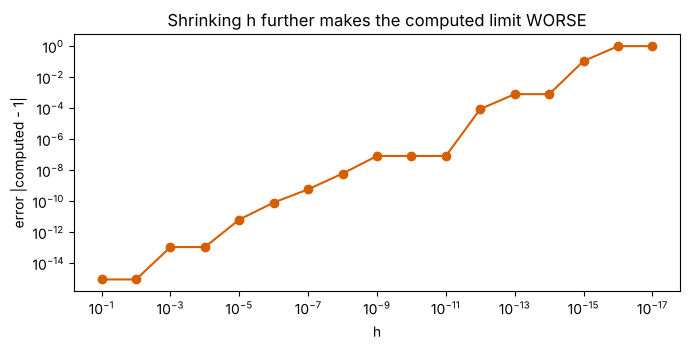

In [15]:
hs = 10.0 ** -np.arange(1, 18)
vals = ((1 + hs) - 1) / hs
for h, v in zip(hs, vals):
    print(f"h = {h:.0e}:  ((1 + h) - 1)/h = {v:.12f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(hs, np.abs(vals - 1) + 1e-17, 'o-', color=PALETTE[1])
ax.set_yscale('log'); ax.set_xlabel('h'); ax.set_ylabel('error |computed - 1|')
ax.set_title('Shrinking h further makes the computed limit WORSE'); ax.invert_xaxis()
plt.tight_layout(); plt.show()

Below $h \approx 10^{-8}$ the error grows, and at $h = 10^{-16}$ the answer is 0. The mathematical limit exists; the computation of it does not survive arbitrarily small steps. Lesson 9 meets this trade-off again for numerical derivatives.

# **Part 5: Continuity and Discontinuities**

A function is **continuous at $a$** if three things hold: $f(a)$ is defined, $\lim_{x \to a}f(x)$ exists, and they are equal. Informally: no gap, no jump, no blow-up, so the graph can be drawn without lifting the pen. Polynomials, exponentials, sigmoids, ReLU and sums, products and compositions of continuous functions are continuous wherever they are defined.

When continuity fails, the way it fails matters:

| Type | What happens at $a$ | Example | Can it be fixed? |
|---|---|---|---|
| **removable** | the limit exists, but $f(a)$ is missing or different | $\sin(x)/x$ at 0; $\frac{x^2 - 1}{x - 1}$ at 1 | yes: define $f(a)$ as the limit |
| **jump** | left and right limits exist but differ | a step activation; voltage reset after a spike | no: it is real |
| **infinite** | the function grows without bound | $1/x$ at 0; $\ln x$ at $0^+$ | no |

**Continuous is not the same as smooth.** ReLU is continuous at 0 but has a corner there; Lesson 9 shows it has no single slope at that point.

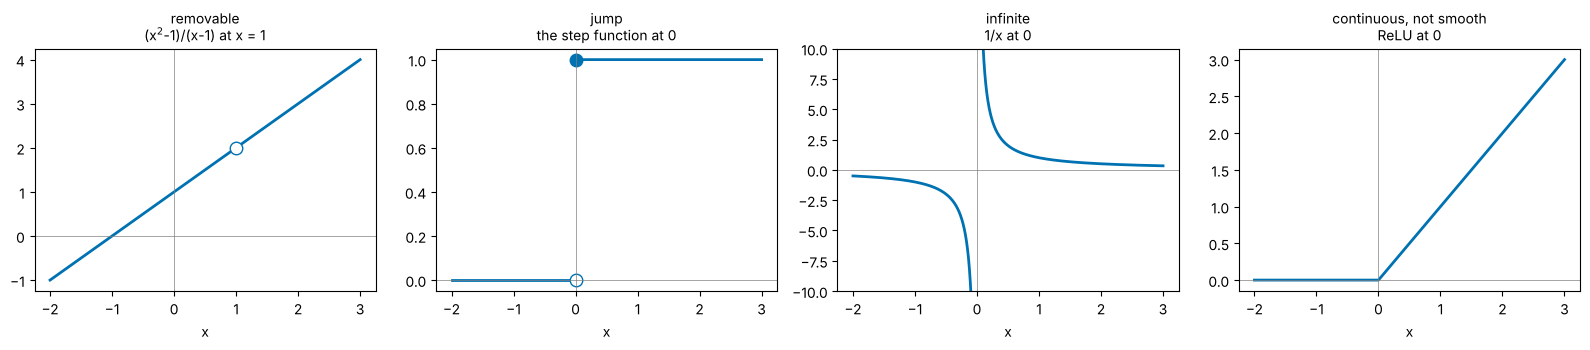

In [16]:
xc = np.linspace(-2, 3, 2001)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
# removable
y_rem = (xc**2 - 1) / np.where(np.isclose(xc, 1), np.nan, xc - 1)
axes[0].plot(xc, y_rem, color=PALETTE[0], lw=2); axes[0].plot(1, 2, 'o', mfc='white', mec=PALETTE[0], ms=9)
axes[0].set_title('removable\n(x$^2$-1)/(x-1) at x = 1', fontsize=10)
# jump
axes[1].plot(xc[xc < 0], np.zeros((xc < 0).sum()), color=PALETTE[0], lw=2); axes[1].plot(xc[xc >= 0], np.ones((xc >= 0).sum()), color=PALETTE[0], lw=2)
axes[1].plot(0, 0, 'o', mfc='white', mec=PALETTE[0], ms=9); axes[1].plot(0, 1, 'o', color=PALETTE[0], ms=9)
axes[1].set_title('jump\nthe step function at 0', fontsize=10)
# infinite
xn, xp = xc[xc < -0.02], xc[xc > 0.02]
axes[2].plot(xn, 1 / xn, color=PALETTE[0], lw=2); axes[2].plot(xp, 1 / xp, color=PALETTE[0], lw=2); axes[2].set_ylim(-10, 10)
axes[2].set_title('infinite\n1/x at 0', fontsize=10)
# continuous with a corner
axes[3].plot(xc, np.maximum(xc, 0), color=PALETTE[0], lw=2)
axes[3].set_title('continuous, not smooth\nReLU at 0', fontsize=10)
for ax in axes:
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5); ax.set_xlabel('x')
plt.tight_layout(); plt.show()

### Why continuity matters: crossing a threshold, and learning

**The intermediate value theorem.** If $f$ is continuous on $[a, b]$ and $f(a) < y < f(b)$, then $f(x) = y$ for some $x$ in between: a continuous curve cannot get from below a level to above it without crossing. This guarantees that a continuous, increasing f-I curve reaches every rate between its extremes at some current, and it justifies **bisection**: halve the interval, keep the half where the sign of $f(x) - y$ changes, repeat. Each step halves the uncertainty, so 30 steps shrink it by a factor of about $10^9$.

In [17]:
def bisection(f, target, lo, hi, n_steps=40):
    # Find x in [lo, hi] with f(x) = target, assuming f is continuous and f(lo) - target, f(hi) - target have opposite signs.
    flo = f(lo) - target
    for _ in range(n_steps):
        mid = (lo + hi) / 2
        fmid = f(mid) - target
        if np.sign(fmid) == np.sign(flo):
            lo, flo = mid, fmid
        else:
            hi = mid
    return (lo + hi) / 2

f_cr = lambda cc: contrast_response(cc, 2, 30, 15, 2.5)
c_star = bisection(f_cr, 20.0, 0.0, 100.0)
print(f"contrast giving 20 spikes/s: {c_star:.6f}%   (check: r = {f_cr(c_star):.8f})")
step = lambda xx: 0.0 if xx < 1.0 else 40.0
x_bad = bisection(step, 20.0, 0.0, 3.0)
print(f"bisection on the STEP function 'finds' x = {x_bad:.6f}, where the rate is {step(x_bad)}: no input gives 20 spikes/s, because the function jumps over it")

contrast giving 20 spikes/s: 17.641185%   (check: r = 20.00000000)
bisection on the STEP function 'finds' x = 1.000000, where the rate is 40.0: no input gives 20 spikes/s, because the function jumps over it


**Learning needs continuity.** The first artificial neurons used a step activation: output 1 if $\mathbf{w}\cdot\mathbf{x} + b > 0$, else 0. A small change in the weights then changes the output either not at all or by a full jump, so there is no gradual signal saying which way to adjust them. Replacing the step by a **continuous** (and smooth) sigmoid, so that small weight changes give small output changes, is what made gradient-based learning possible (Lessons 10 and 12). The step is the limit of ever-steeper sigmoids, $\sigma(kx)$ as $k \to \infty$, which keeps the shape but loses the gradual change.

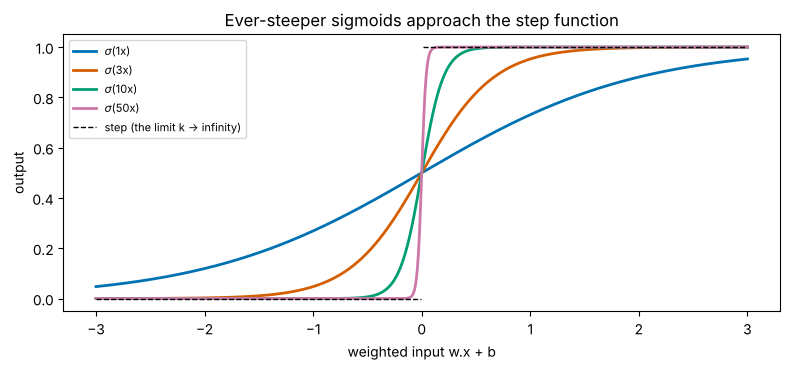

In [18]:
xs5 = np.linspace(-3, 3, 601)
fig, ax = plt.subplots(figsize=(8, 3.8))
for k_, colour in zip([1, 3, 10, 50], PALETTE):
    ax.plot(xs5, sigmoid(k_ * xs5), color=colour, lw=2, label=f'$\\sigma$({k_}x)')
ax.plot(xs5[xs5 < 0], np.zeros((xs5 < 0).sum()), 'k--', lw=1, label='step (the limit k -> infinity)'); ax.plot(xs5[xs5 > 0], np.ones((xs5 > 0).sum()), 'k--', lw=1)
ax.set_xlabel('weighted input w.x + b'); ax.set_ylabel('output'); ax.set_title('Ever-steeper sigmoids approach the step function'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# **Part 6: Sampling and Plotting Pitfalls**

A computer never sees a function, only its values at the points you choose. `plt.plot` then joins those points with straight lines. Three things can go wrong.

1. **Undersampling a fast oscillation (aliasing).** A 9 Hz rhythm sampled 10 times per second looks like a slow 1 Hz rhythm. To see an oscillation you need more than **two samples per cycle** (the Nyquist rate); to see its shape, many more.
2. **Missing a narrow feature.** A brief peak can fall between grid points and vanish.
3. **Joining across a discontinuity.** Straight lines drawn across a jump or a vertical asymptote create steep segments that are not part of the function.

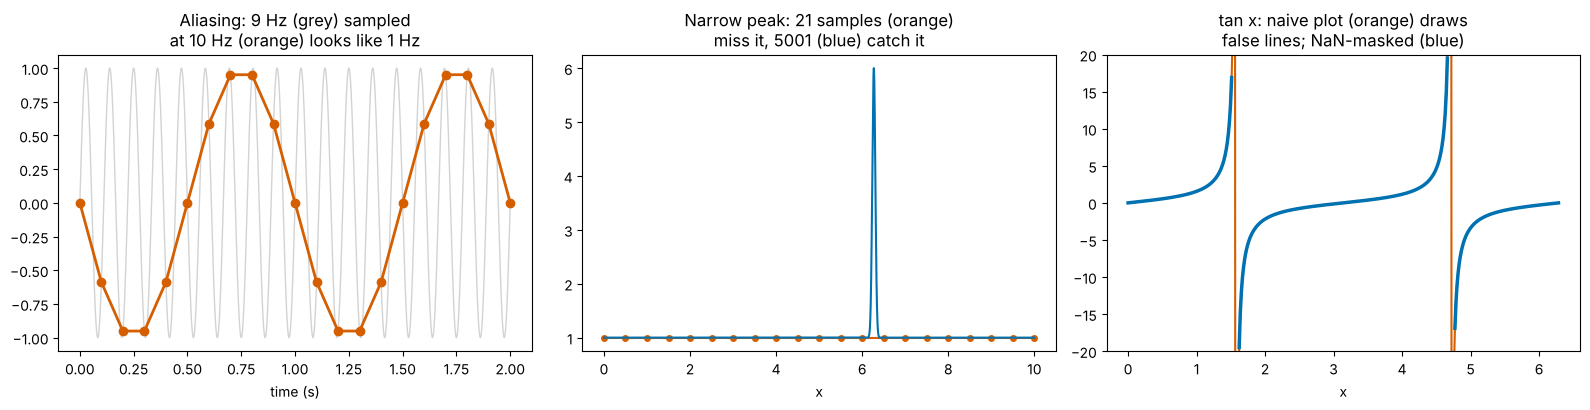

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
# 1. aliasing
t_fine = np.linspace(0, 2, 4001); f_true = 9.0
axes[0].plot(t_fine, np.sin(2 * np.pi * f_true * t_fine), color='lightgrey', lw=1, label='true 9 Hz signal')
t_s = np.arange(0, 2.0001, 1 / 10)
axes[0].plot(t_s, np.sin(2 * np.pi * f_true * t_s), 'o-', color=PALETTE[1], lw=2, label='sampled at 10 Hz: looks like 1 Hz')
axes[0].set_xlabel('time (s)'); axes[0].set_title('Aliasing: 9 Hz (grey) sampled\nat 10 Hz (orange) looks like 1 Hz')
# 2. narrow peak
xp6 = np.linspace(0, 10, 5001)
peak = lambda xx: 1 + 5 * np.exp(-((xx - 6.27) / 0.05)**2)
for n_pts, colour in [(21, PALETTE[1]), (5001, PALETTE[0])]:
    xx = np.linspace(0, 10, n_pts)
    axes[1].plot(xx, peak(xx), 'o-' if n_pts < 100 else '-', ms=4, color=colour, lw=1.5, label=f'{n_pts} sample points')
axes[1].set_xlabel('x'); axes[1].set_title('Narrow peak: 21 samples (orange)\nmiss it, 5001 (blue) catch it')
# 3. joining across a vertical asymptote
xa = np.linspace(0, 2 * np.pi, 400)
axes[2].plot(xa, np.tan(xa), color=PALETTE[1], lw=1.5, label='plt.plot(x, tan x): false vertical lines')
y_masked = np.where(np.abs(np.tan(xa)) > 20, np.nan, np.tan(xa))
axes[2].plot(xa, y_masked, color=PALETTE[0], lw=2.5, label='large values masked with NaN')
axes[2].set_ylim(-20, 20); axes[2].set_xlabel('x'); axes[2].set_title('tan x: naive plot (orange) draws\nfalse lines; NaN-masked (blue)')
plt.tight_layout(); plt.show()

#### Interactive version: how many samples does a 9 Hz rhythm need?

Increase the sampling rate. Below 18 samples per second (twice 9 Hz) the dots trace a false, slower rhythm; just above it the frequency is right but the shape is crude; only with many samples per cycle does the curve look like the signal.

In [20]:
rates_s = [5, 8, 10, 12, 16, 19, 25, 40, 80, 200]
def sampled(fs):
    tt = np.arange(0, 2.0001, 1 / fs)
    return tt, np.sin(2 * np.pi * 9 * tt)
tt0, yy0 = sampled(rates_s[0])
t_bg = np.linspace(0, 2, 2001)
fig_alias = go.Figure([go.Scatter(x=t_bg, y=np.round(np.sin(2 * np.pi * 9 * t_bg), 3), mode='lines', line=dict(color='lightgrey'), name='true 9 Hz signal'),
                       go.Scatter(x=tt0, y=yy0, mode='lines+markers', line=dict(color=PALETTE[1], width=2), name='samples, joined')])
fig_alias.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=sampled(fs)[0], y=sampled(fs)[1])],
                             layout=go.Layout(title=f'sampling at {fs} Hz = {fs / 9:.1f} samples per cycle' + ('   (below Nyquist: aliased)' if fs < 18 else '')))
                    for k, fs in enumerate(rates_s)]
buttons, sliders = play_pause_and_slider(rates_s, prefix='sampling rate (Hz) = ', duration=700)
fig_alias.update_layout(title=fig_alias.frames[0].layout.title.text, xaxis_title='time (s)', yaxis_title='signal', template='plotly_white',
                        width=850, height=460, updatemenus=buttons, sliders=sliders)
fig_alias.show(config=PLOTLY_CONFIG)

**In neural data** these pitfalls are everywhere. Spike waveforms last about 1 ms and need sampling at 20–30 kHz; local field potentials sampled at 1 kHz cannot show anything above 500 Hz; a 50 ms bin cannot resolve a 10 ms burst. And the motivating example of this lesson is the same problem along a stimulus axis: four contrasts cannot reveal the shape of a contrast-response function between them. **Sample densely where the function changes quickly, and never trust a curve between or beyond the points that support it.**

# **Part 7: Mini-Lab — What Function Describes a Neuron's Response to Speed?**

We return to the motor-cortex recording used since Lesson 2: 171 neurons in monkey primary motor cortex during centre-out reaches, in 50 ms bins ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)). Earlier lessons used movement **direction**. Here the input variable is hand **speed** $s$ (cm/s), and the question is: what function $r = f(s)$ best describes a neuron's firing rate?

**Plan.**
1. Choose the neuron whose rate is most correlated with speed **in the first half** of the session, and align rate with the speed 100 ms later (motor cortex leads movement).
2. Estimate the response function empirically by **binning** speed, and see how the choice of bins changes the picture (Part 6 on real data).
3. Fit five function families on the first half and compare them on the second half.
4. Read the **limits** $s \to 0^+$ and $s \to \infty$ from each fitted function, and ask which of them the data support.

To fit a nonlinear function we use `scipy.optimize.curve_fit`, which searches for the parameters that minimise the squared error. For now treat it as a tool; Lessons 12–15 open the box.

In [21]:
import os, urllib.request
from scipy.io import loadmat
from scipy.optimize import curve_fit

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
rates_all = m1['spikes'].T.astype(float) / 0.05                      # shape (15536, 171): (time bin, neuron), spikes/s
vel = m1['handVel'][:2].T * 100                                        # shape (15536, 2): hand velocity, cm/s
speed_all = np.linalg.norm(vel, axis=1)                                # shape (15536,): hand speed, cm/s

LAG = 2                                                                # 2 bins = 100 ms: rate at t is compared with speed at t + 100 ms
rate_lag = rates_all[:-LAG]                                            # shape (15534, 171)
speed = speed_all[LAG:]                                                # shape (15534,)
n_bins = speed.size
train = np.arange(n_bins) < n_bins // 2                                # first half: choose and fit; second half: test

corr_train = np.array([np.corrcoef(rate_lag[train, i], speed[train])[0, 1] if rate_lag[train, i].std() > 0 else 0 for i in range(rate_lag.shape[1])])
best = int(np.argmax(corr_train))
y = rate_lag[:, best]                                                  # this neuron's rate, spikes/s, shape (15534,)
print(f"chosen neuron: {best}, correlation with speed (first half): {corr_train[best]:.2f}, mean rate {y.mean():.1f} spikes/s")
print("speed percentiles 10/50/90/99%:", np.round(np.percentile(speed, [10, 50, 90, 99]), 1), "cm/s;  maximum", round(speed.max(), 1))
print("single-bin rates take only multiples of 20 spikes/s (one spike per 50 ms):", np.unique(y)[:6], '...')

chosen neuron: 120, correlation with speed (first half): 0.40, mean rate 60.3 spikes/s
speed percentiles 10/50/90/99%: [ 0.5  3.1 12.8 29.3] cm/s;  maximum 43.4
single-bin rates take only multiples of 20 spikes/s (one spike per 50 ms): [  0.  20.  40.  60.  80. 100.] ...


A single 50 ms bin holds 0, 1, 2, ... spikes, so its "rate" is 0, 20, 40, ... spikes/s: far too coarse to see a smooth function. Averaging the rate over all bins with similar speeds estimates the underlying function $f(s)$. But **how** to group speeds is itself a sampling choice. The speed distribution is very skewed (half of all bins are slower than 3 cm/s), so equal-width bins put thousands of samples in the first bin and a handful in the last.

4 equal-width bins (0-40 cm/s)    : 4 usable bins, samples per bin from 76 to 6621
40 equal-width bins (0-40 cm/s)   : 39 usable bins, samples per bin from 2 to 1539
20 equal-count bins (quantiles)   : 20 usable bins, samples per bin from 388 to 389


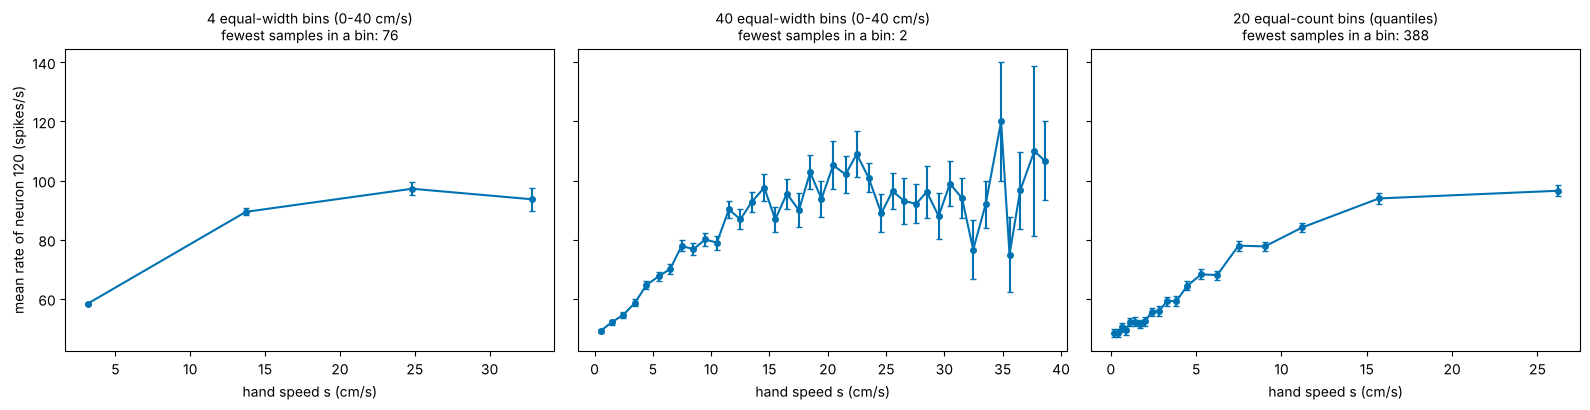

In [22]:
def binned_curve(edges, s=speed[train], r=y[train]):
    mids, means, sems, counts = [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        k = (s >= a) & (s < b)
        if k.sum() >= 2:
            mids.append(s[k].mean()); means.append(r[k].mean()); sems.append(r[k].std(ddof=1) / np.sqrt(k.sum())); counts.append(k.sum())
    return np.array(mids), np.array(means), np.array(sems), np.array(counts)

schemes = {'4 equal-width bins (0-40 cm/s)': np.linspace(0, 40, 5),
           '40 equal-width bins (0-40 cm/s)': np.linspace(0, 40, 41),
           '20 equal-count bins (quantiles)': np.quantile(speed[train], np.linspace(0, 1, 21)) + np.r_[np.zeros(20), 1e-9]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (name, edges) in zip(axes, schemes.items()):
    mids, means, sems, counts = binned_curve(edges)
    ax.errorbar(mids, means, yerr=sems, fmt='o-', ms=4, color=PALETTE[0], capsize=2)
    ax.set_title(f'{name}\nfewest samples in a bin: {counts.min()}', fontsize=10); ax.set_xlabel('hand speed s (cm/s)')
    print(f"{name:<34}: {len(mids)} usable bins, samples per bin from {counts.min()} to {counts.max()}")
axes[0].set_ylabel(f'mean rate of neuron {best} (spikes/s)')
plt.tight_layout(); plt.show()

Four bins hide the shape. Forty equal-width bins show it at low speeds but become noisy and sparse at high speeds, where very few samples exist (error bars are $\pm 1$ standard error of the mean). Equal-count bins give every point the same support, and place points densely where the data are dense. All three describe the same neuron, and only the third shows clearly that the rate **rises and then levels off**.

### Fitting five function families

Five candidate functions, each with parameters fitted to the **training half** by least squares (on single bins, not on the binned means):

| Family | $f(s)$ | Behaviour as $s \to \infty$ |
|---|---|---|
| constant | $a$ | $a$ |
| linear | $a + bs$ | grows without bound |
| threshold-linear (ReLU) | $a + b\max(0, s - s_{\text{th}})$ | grows without bound |
| saturating exponential | $r_0 + A(1 - e^{-s/s_0})$ | $r_0 + A$ |
| logistic | $r_0 + \dfrac{A}{1 + e^{-k(s - s_{50})}}$ | $r_0 + A$ |

In [23]:
families = {
    'constant':               (lambda s, a: a + 0 * s,                                   [50.0]),
    'linear':                 (lambda s, a, b: a + b * s,                                [45.0, 2.0]),
    'threshold-linear':       (lambda s, a, b, th: a + b * np.maximum(s - th, 0),        [45.0, 3.0, 2.0]),
    'saturating exponential': (lambda s, r0, A, s0: r0 + A * (1 - np.exp(-s / s0)),       [45.0, 50.0, 8.0]),
    'logistic':               (lambda s, r0, A, k, s50: r0 + A / (1 + np.exp(-k * (s - s50))), [45.0, 50.0, 0.3, 8.0]),
}
fits = {}
var_test = np.var(y[~train])
for name, (f, p0) in families.items():
    params, _ = curve_fit(f, speed[train], y[train], p0=p0, maxfev=20000)
    r2_test = 1 - np.mean((y[~train] - f(speed[~train], *params))**2) / var_test
    fits[name] = (f, params, r2_test)
    print(f"{name:<23} parameters {np.round(params, 2)}   test R^2 = {r2_test:.3f}")

constant                parameters [63.3]   test R^2 = -0.030
linear                  parameters [51.77  2.17]   test R^2 = 0.161
threshold-linear        parameters [39.81  2.17 -5.52]   test R^2 = 0.161
saturating exponential  parameters [44.79 59.83 10.99]   test R^2 = 0.198
logistic                parameters [33.58 63.53  0.25  5.04]   test R^2 = 0.199


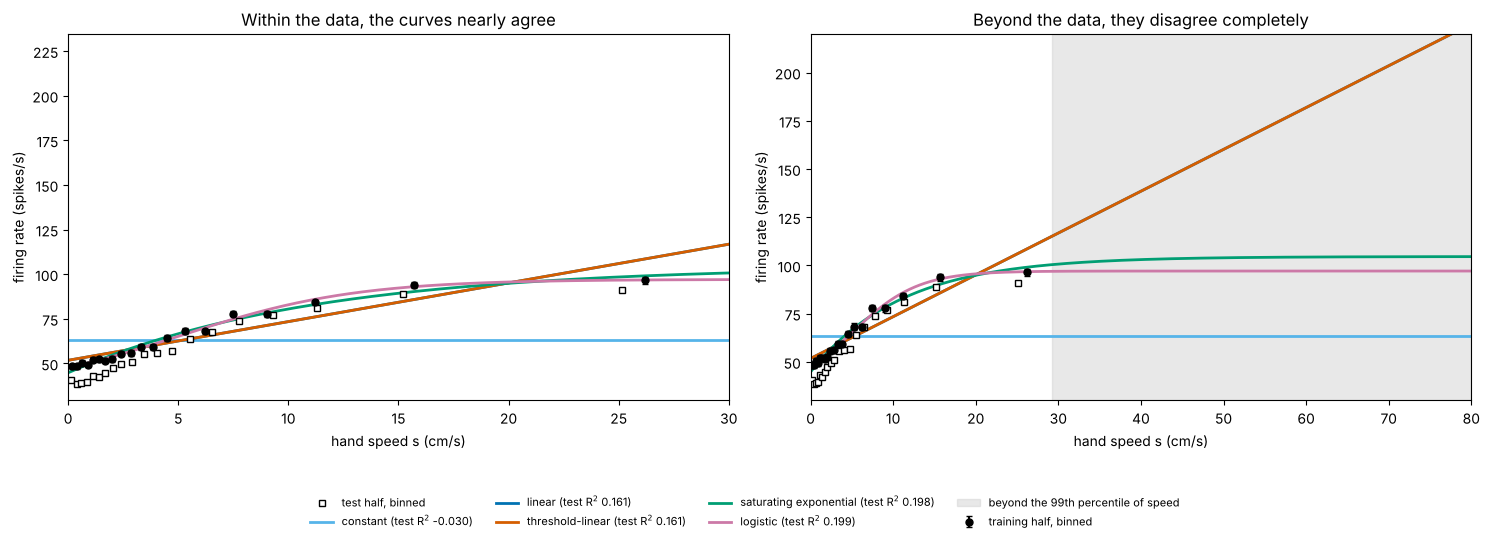

In [24]:
mids_q, means_q, sems_q, _ = binned_curve(schemes['20 equal-count bins (quantiles)'])
mids_te, means_te, _, _ = binned_curve(np.quantile(speed[~train], np.linspace(0, 1, 21)) + np.r_[np.zeros(20), 1e-9], s=speed[~train], r=y[~train])
s_grid = np.linspace(0, 80, 801)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, xmax in [(axes[0], 30), (axes[1], 80)]:
    ax.errorbar(mids_q, means_q, yerr=sems_q, fmt='o', color='black', ms=5, capsize=2, label='training half, binned', zorder=4)
    ax.plot(mids_te, means_te, 's', mfc='white', mec='black', ms=5, label='test half, binned', zorder=4)
    for (name, (f, params, r2)), colour in zip(fits.items(), [PALETTE[5]] + PALETTE):
        ax.plot(s_grid, f(s_grid, *params), color=colour, lw=2, label=f'{name} (test R$^2$ {r2:.3f})')
    ax.set_xlim(0, xmax); ax.set_xlabel('hand speed s (cm/s)'); ax.set_ylabel('firing rate (spikes/s)')
axes[1].axvspan(np.percentile(speed, 99), 80, color='lightgrey', alpha=0.5, label='beyond the 99th percentile of speed')
axes[0].set_title('Within the data, the curves nearly agree'); axes[1].set_title('Beyond the data, they disagree completely')
axes[1].set_ylim(30, 220)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.13, 1, 1)); plt.show()

### Reading the limits

Each fitted function makes a claim about the neuron at very low speeds ($s \to 0^+$) and at very high speeds ($s \to \infty$). Evaluating the function at tiny and huge speeds, and comparing with the formula, gives the limits.

In [25]:
print(f"{'family':<23} {'s -> 0+':>10} {'s = 60':>10} {'s -> infinity':>16}")
for name, (f, params, r2) in fits.items():
    at0 = f(1e-9, *params)
    at60 = f(60.0, *params)
    big = f(1e6, *params)
    lim_inf = f"{big:.1f}" if abs(big) < 1e4 else "unbounded"
    print(f"{name:<23} {at0:>10.1f} {at60:>10.1f} {lim_inf:>16}")
slow = speed < 0.5
print(f"\nmeasured: mean rate when the hand is nearly still (s < 0.5 cm/s): {y[slow].mean():.1f} spikes/s;"
      f"  bins faster than 30 cm/s: {(speed > 30).sum()} of {n_bins} ({(speed > 30).mean():.1%})")

family                     s -> 0+     s = 60    s -> infinity
constant                      63.3       63.3             63.3
linear                        51.8      181.9        unbounded
threshold-linear              51.8      181.9        unbounded
saturating exponential        44.8      104.4            104.6
logistic                      47.6       97.1             97.1

measured: mean rate when the hand is nearly still (s < 0.5 cm/s): 44.0 spikes/s;  bins faster than 30 cm/s: 122 of 15534 (0.8%)


**Interpretation.** The two saturating families describe this neuron best (test $R^2$ about 0.20, against 0.16 for a straight line), and the binned curves show why: the rate rises steeply at low speeds and levels off. The threshold-linear fit put its threshold below zero speed, where there are no data, and so collapsed onto the straight line (the two lines coincide in the figure): a threshold the data cannot locate is not identifiable.

The limits tell a cautionary story. As $s \to 0^+$, the two saturating functions agree with the measured rate of the still hand (44.0 spikes/s) to within 4 spikes/s; the straight line, which cannot bend, overshoots by 8. At high speeds the fits part company. The two saturating functions, with nearly identical test scores, put the ceiling (the limit as $s \to \infty$) about 7 spikes/s apart; the linear and threshold-linear fits have no ceiling at all. Fewer than 1% of bins are faster than 30 cm/s, so **the data do not determine the asymptote**; the choice of family does. The logistic's parameter $r_0 = 33.7$ is not the rate at zero speed (that is about 48 spikes/s); it is the limit as $s \to -\infty$, a speed that does not exist.

Three more cautions. At low speeds the test-half rates sit 5–10 spikes/s below the training half (open squares versus dots): the neuron's baseline drifted during the session, which no function of speed alone can capture. The test $R^2$ values are low because single 50 ms bins are dominated by spiking noise (rates jump in steps of 20 spikes/s), not because the function is poor. And speed is not the only thing driving this neuron: direction matters too (Lesson 2), so $f(s)$ is an average over directions.

**Limitations.** One neuron, chosen for its speed correlation on the training half. The 100 ms lag was fixed, not fitted. `curve_fit` can stop at a poor local solution, especially for the four-parameter logistic. Exercise 7 asks whether these functions can predict fast movements from slow ones.

# **Part 8: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Function with parameters | tuning curves, contrast-response and f-I curves; parameters compared across neurons and conditions | a model is a parametrised function; training chooses parameters |
| Composition | input → synaptic current → membrane potential → rate | layers of a deep network; the chain rule (Lesson 10) |
| Inverse | decoding a stimulus from a rate; inverting a calibration curve | logit and log links; inverting a normalising flow |
| Exponential and logarithm | membrane decay, synaptic currents, Weber–Fechner perception | softmax, cross-entropy and log-likelihoods |
| Sigmoid, tanh, ReLU, softplus | firing probability, saturating rate models, threshold-linear neurons | activation functions |
| Limits and asymptotes | spontaneous rate, saturation, refractory ceiling on rate | saturating activations and vanishing gradients (Lesson 10) |
| Continuity | rate is continuous at threshold in integrate-and-fire neurons; spikes and resets are jumps | gradient-based learning needs continuous, smooth losses and activations |
| Sampling | Nyquist rate for spikes and LFPs; bin size; stimulus spacing | input resolution; evaluating a model only where it was trained |

**Gain modulation** is a particularly neat neuroscience example of parameters: attention, locomotion or arousal often change a sensory neuron's response function by **scaling** it ($A f(x)$: multiplicative gain) or **shifting** it ($f(x - a)$: a change in sensitivity), and experiments distinguish the two by fitting the parameters in each condition.

# **Part 9: Summary and Lesson 9 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Function | $f: \text{domain} \to \text{codomain}$ | one output per input; state the domain and units |
| Variables vs parameters | $f(x;\, \theta)$ | the variable changes per input; parameters per neuron or model |
| Transformations | $f(x - a)$, $f(x/s)$, $A f(x)$, $f(x) + b$ | shift right, stretch, scale, raise |
| Composition | $(f \circ g)(x) = f(g(x))$ | inside first; order matters |
| Inverse | $f^{-1}(f(x)) = x$; `np.interp`, bisection | needs one-to-one (horizontal line test) |
| Exponential, logarithm | $e^{a+b} = e^ae^b$, $\ln(ab) = \ln a + \ln b$ | exponentials are straight lines on a log axis |
| Limit | $\lim_{x \to a} f(x)$ | what $f$ approaches; $f(a)$ itself is irrelevant |
| One-sided limits, asymptotes | $x \to a^\pm$, $x \to \pm\infty$ | the two-sided limit needs both sides to agree |
| Continuity | $\lim_{x \to a} f(x) = f(a)$ | removable, jump and infinite discontinuities; continuous ≠ smooth |
| Sampling | more than 2 samples per cycle; dense where $f$ changes fast | aliasing, missed peaks, false lines across jumps; never trust a curve beyond its data |

**Lesson 9 — Derivatives and sensitivity** asks how fast a function changes. The answer is a limit you have already met: the slope of the line through two nearby points, $\frac{f(x + h) - f(x)}{h}$, as $h \to 0$. It measures **sensitivity**: how much the firing rate changes per unit change of speed, contrast or current. It also inherits the floating-point trap of Part 4.